# Bài 4 — Phân đoạn ảnh dựa trên vùng

Thực hiện Region Growing, K-means, SLIC và Felzenszwalb. Các đầu ra có ý nghĩa khác nhau; so sánh trên cùng ảnh chỉ mang tính mô tả nếu không có mask tham chiếu.


In [1]:
from pathlib import Path
import sys, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import felzenszwalb, mark_boundaries
from skimage.color import label2rgb
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    raise FileNotFoundError("Run from repository root or notebooks/")
sys.path.insert(0, str(ROOT))
from src.region_segmentation import my_region_growing, run_kmeans_segmentation, run_slic_superpixels
names = {
 "weld": ("CH10", "Fig1051(a)(defective_weld).tif"),
 "iceberg": ("CH10", "Fig1045(a)(iceberg).tif"),
 "strawberries": ("CH06", "Fig0630(01)(strawberries_fullcolor).tif"),
 "lenna": ("CH06", "Fig0638(a)(lenna_RGB).tif"),
}
images={}
for name, (chapter, filename) in names.items():
    path=ROOT / "data" / f"DIP3E_Original_Images_{chapter}" / filename
    flag=cv2.IMREAD_COLOR if chapter == "CH06" else cv2.IMREAD_GRAYSCALE
    image=cv2.imread(str(path), flag)
    if image is None:
        raise FileNotFoundError(path)
    images[name]=cv2.cvtColor(image,cv2.COLOR_BGR2RGB) if image.ndim==3 else image
    print(name,filename,images[name].shape)
OUT=ROOT / "outputs" / "bai_4"
def figure(folder, filename, panels, titles, cols=4):
    path=OUT / folder; path.mkdir(parents=True,exist_ok=True)
    rows=(len(panels)+cols-1)//cols
    fig,axes=plt.subplots(rows,cols,figsize=(4*cols,3.8*rows),squeeze=False)
    for ax,img,title in zip(axes.flat,panels,titles):
        ax.imshow(img,cmap="gray" if img.ndim==2 else None)
        ax.set_title(title,fontsize=9); ax.axis("off")
    for ax in axes.flat[len(panels):]: ax.axis("off")
    fig.tight_layout(); fig.savefig(path / filename,dpi=150,bbox_inches="tight")
    plt.show(); plt.close(fig)


weld Fig1051(a)(defective_weld).tif (482, 566)
iceberg Fig1045(a)(iceberg).tif (533, 566)
strawberries Fig0630(01)(strawberries_fullcolor).tif (666, 666, 3)
lenna Fig0638(a)(lenna_RGB).tif (512, 512, 3)


## 1. Region Growing

Duyệt BFS với 8 láng giềng, so sánh với cường độ seed. Khi nhiều seed gặp nhau, pixel thuộc vùng được tiếp cận trước. Các tọa độ được ghi dưới dạng (hàng, cột).


Seed (y,x), cường độ: [((250, 135), 255), ((200, 270), 124), ((248, 295), 216), ((237, 435), 216)]


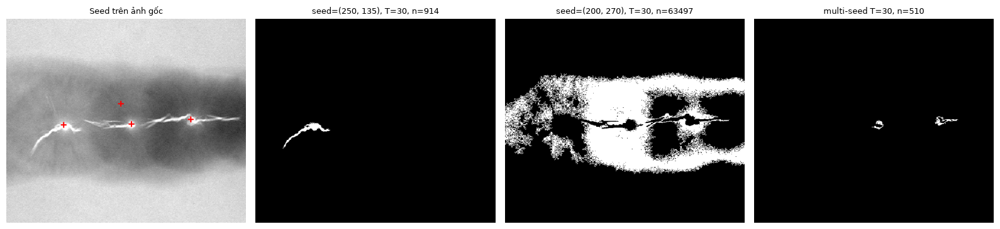

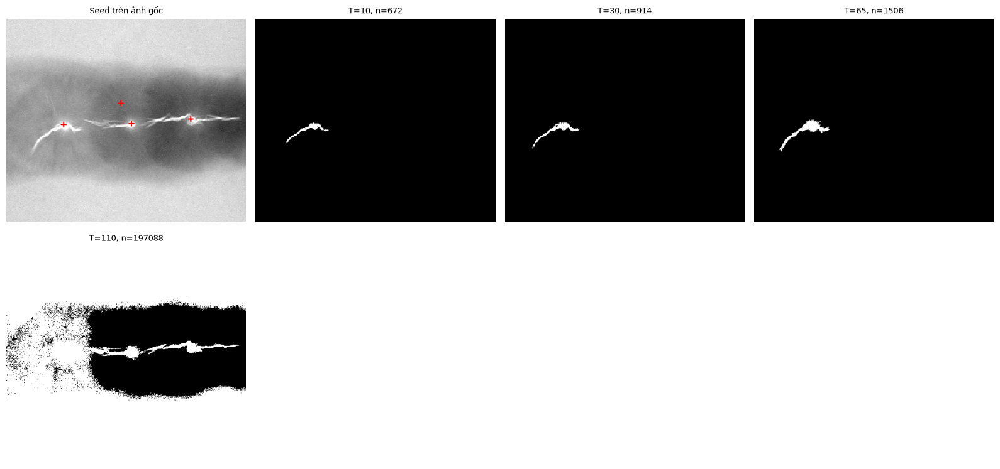

Iceberg seed (266, 283) intensity 49 area 124617


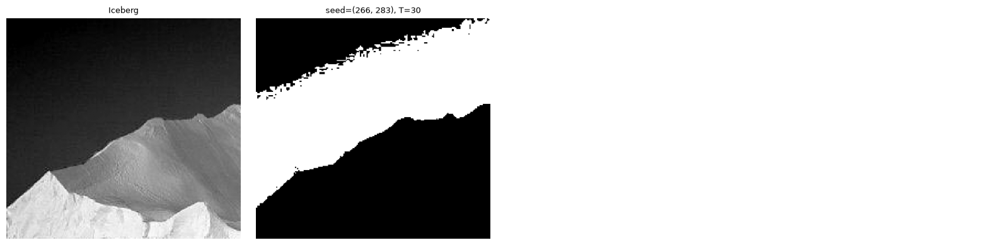

In [2]:
weld=images["weld"]
seeds=[(250,135),(200,270),(248,295),(237,435)]
print("Seed (y,x), cường độ:", [(p,int(weld[p])) for p in seeds])
marked=cv2.cvtColor(weld,cv2.COLOR_GRAY2RGB)
for y,x in seeds: cv2.drawMarker(marked,(x,y),(255,0,0),cv2.MARKER_CROSS,13,2)
panels=[marked]; titles=["Seed trên ảnh gốc"]
for seed in seeds[:2]:
    mask=my_region_growing(weld,[seed],30)
    panels.append(mask); titles.append(f"seed={seed}, T=30, n={np.count_nonzero(mask)}")
multi=my_region_growing(weld,seeds[2:],30)
panels.append(multi); titles.append(f"multi-seed T=30, n={np.count_nonzero(multi)}")
figure("4.1_region_growing","4.1_weld_input_vs_output_seed_positions.png",panels,titles)
panels=[marked]; titles=["Seed trên ảnh gốc"]
for t in (10,30,65,110):
    mask=my_region_growing(weld,[seeds[0]],t)
    panels.append(mask); titles.append(f"T={t}, n={np.count_nonzero(mask)}")
figure("4.1_region_growing","4.1_weld_input_vs_output_threshold_survey.png",panels,titles)
ice=images["iceberg"]
ice_seed=(ice.shape[0]//2,ice.shape[1]//2)
ice_mask=my_region_growing(ice,[ice_seed],30)
print("Iceberg seed", ice_seed, "intensity", int(ice[ice_seed]), "area", np.count_nonzero(ice_mask))
figure("4.1_region_growing","4.1_iceberg_input_vs_output_region_growing.png",
       [ice,ice_mask],["Iceberg",f"seed={ice_seed}, T=30"])


## 2. K-means và SLIC

K-means dùng RNG seed 42 và ba lần khởi tạo. SLIC ghi số lượng vùng thực tế; `n_segments` là số mục tiêu.


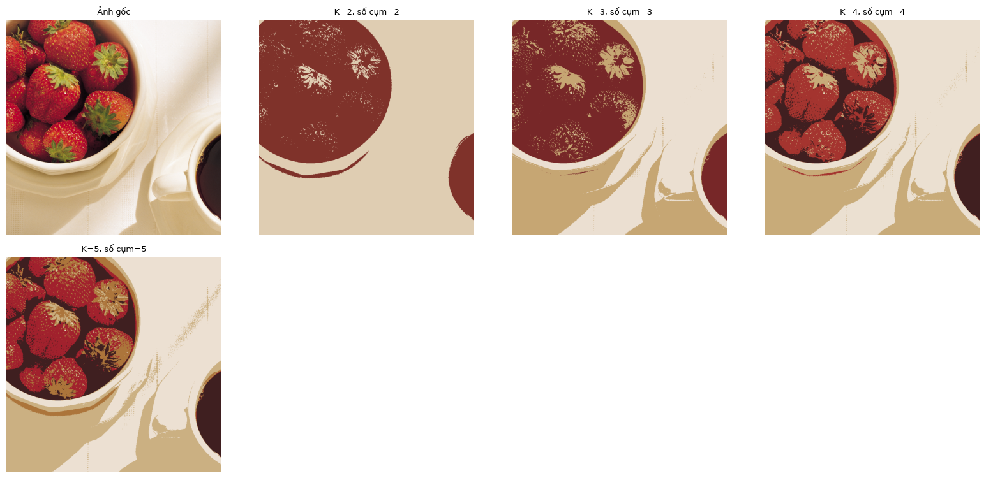

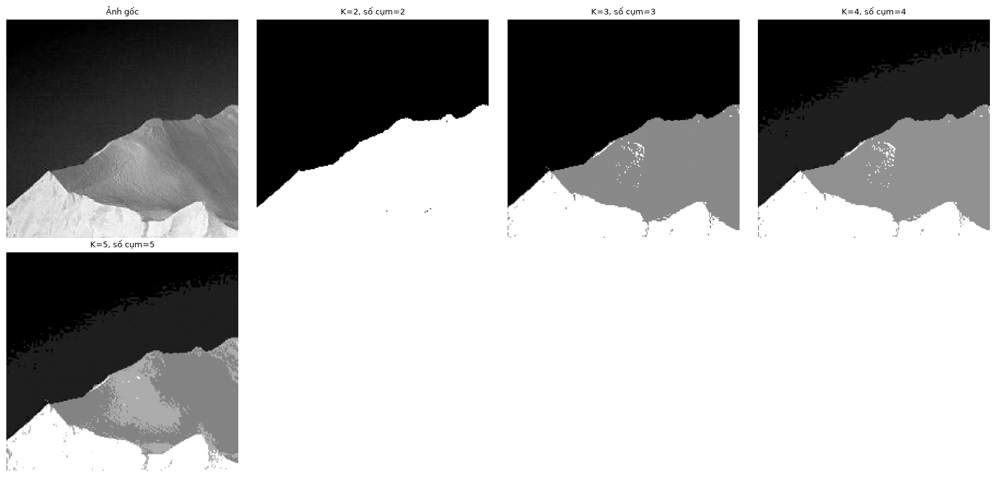

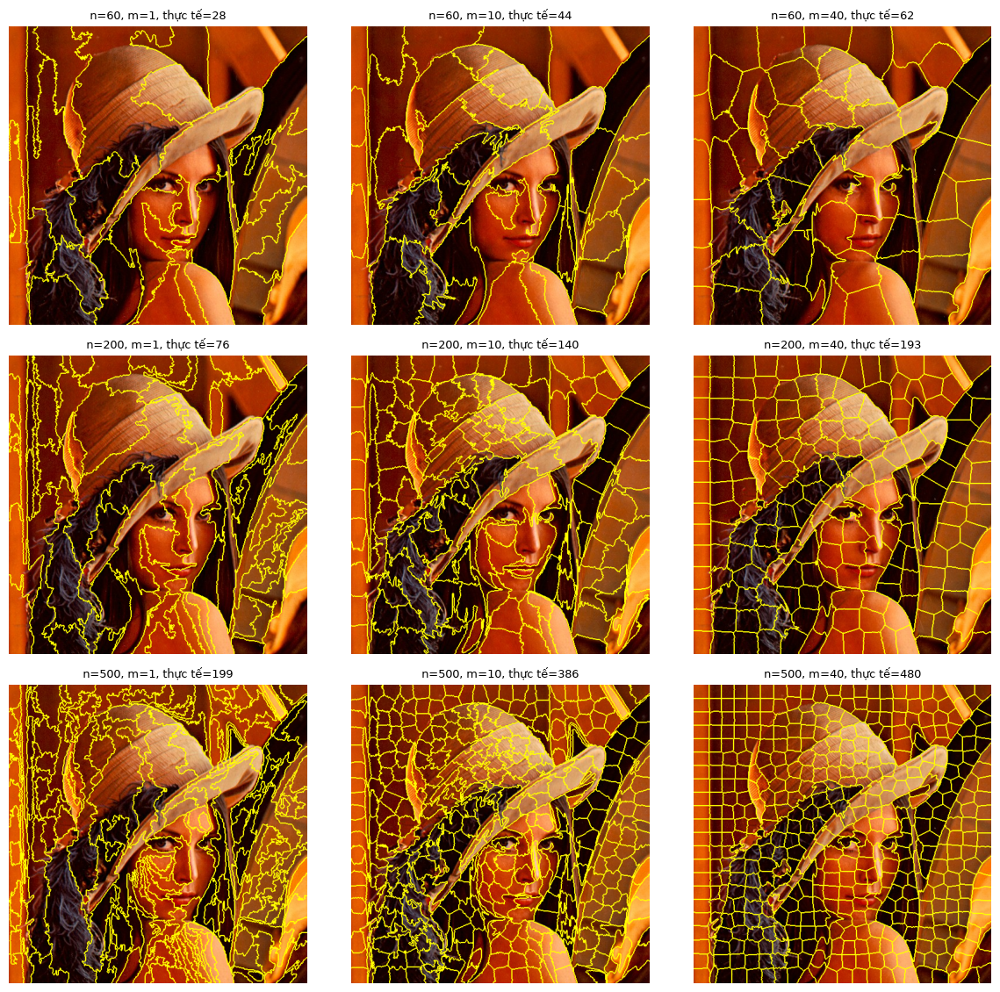

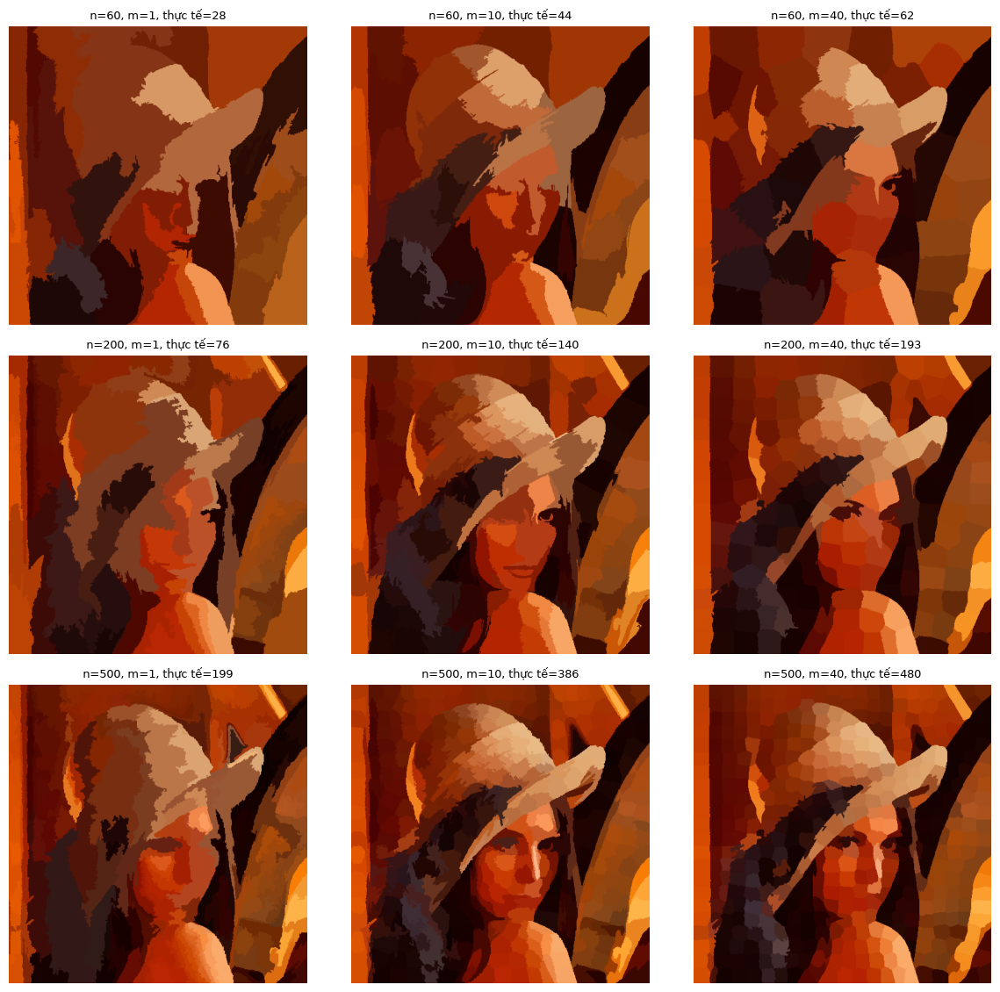

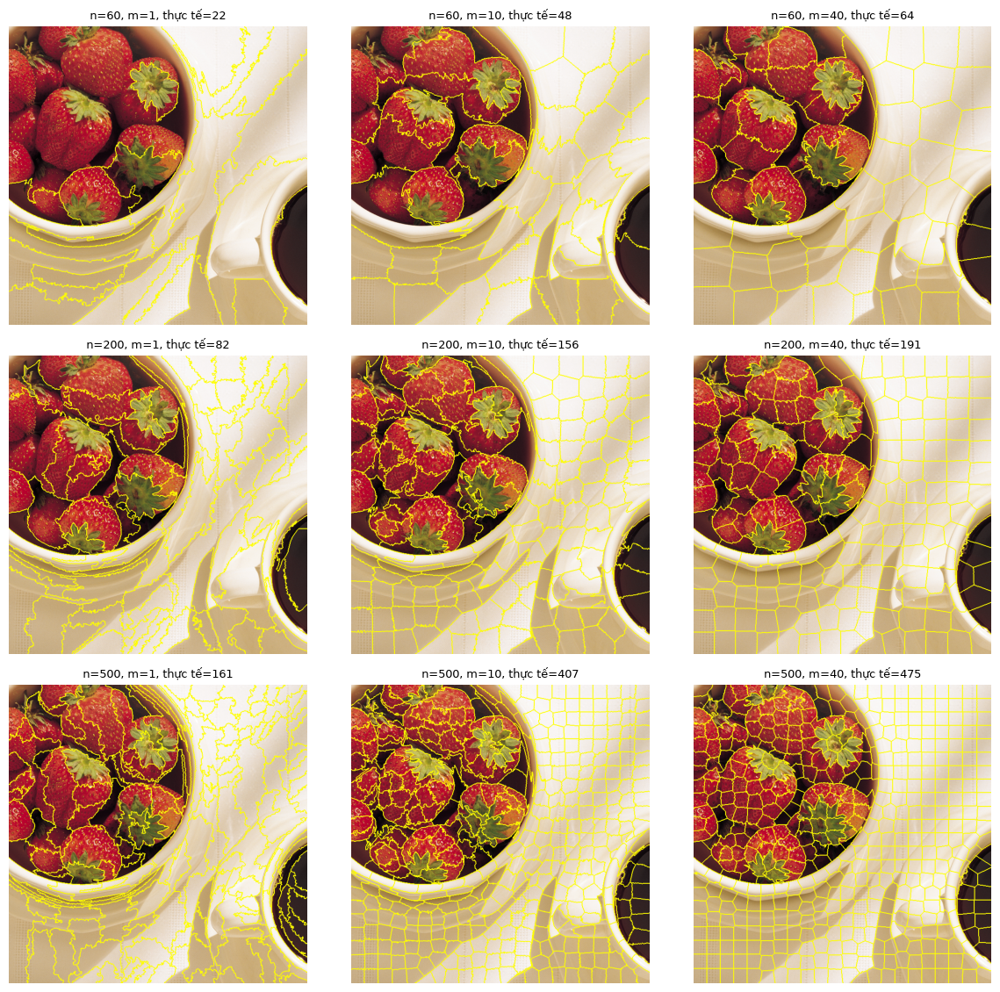

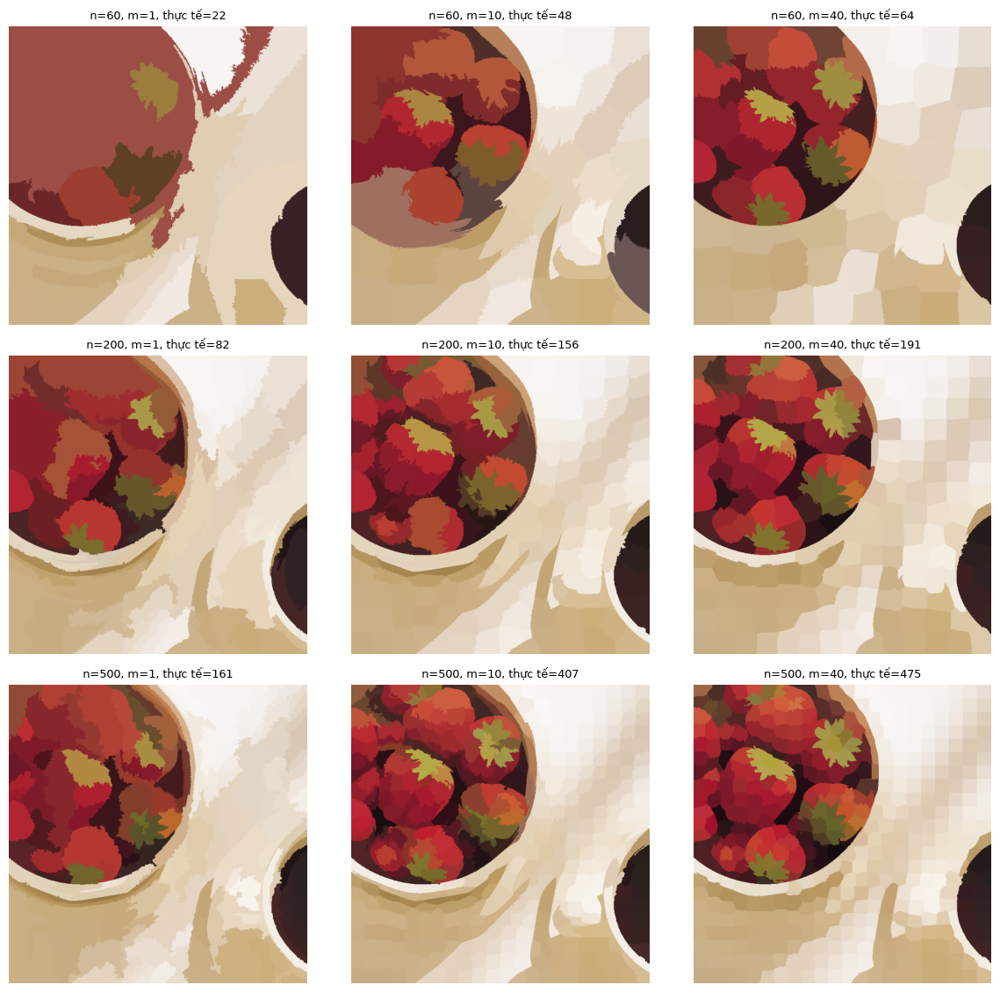

In [3]:
for name in ("strawberries","iceberg"):
    image=images[name]; panels=[image]; titles=["Ảnh gốc"]
    for k in (2,3,4,5):
        reconstructed,labels=run_kmeans_segmentation(image,k)
        panels.append(reconstructed); titles.append(f"K={k}, số cụm={len(np.unique(labels))}")
    figure("4.2_kmeans_and_slic",f"4.2_{name}_input_vs_output_kmeans_k2_to_k5.png",panels,titles)
for name in ("lenna","strawberries"):
    image=images[name]; boundaries=[]; averages=[]; titles=[]
    for n in (60,200,500):
        for compactness in (1,10,40):
            labels=run_slic_superpixels(image,n,compactness)
            boundaries.append(mark_boundaries(image,labels))
            averages.append(label2rgb(labels,image,kind="avg"))
            titles.append(f"n={n}, m={compactness}, thực tế={len(np.unique(labels))}")
    figure("4.2_kmeans_and_slic",f"4.2_{name}_slic_boundaries.png",boundaries,titles,3)
    figure("4.2_kmeans_and_slic",f"4.2_{name}_slic_average.png",averages,titles,3)


## 3. Felzenszwalb và so sánh

Các tham số scale và min_size được khảo sát trên ảnh màu. Bảng thời gian chỉ mô tả lần chạy trong môi trường hiện tại; các phương pháp có loại đầu ra khác nhau.


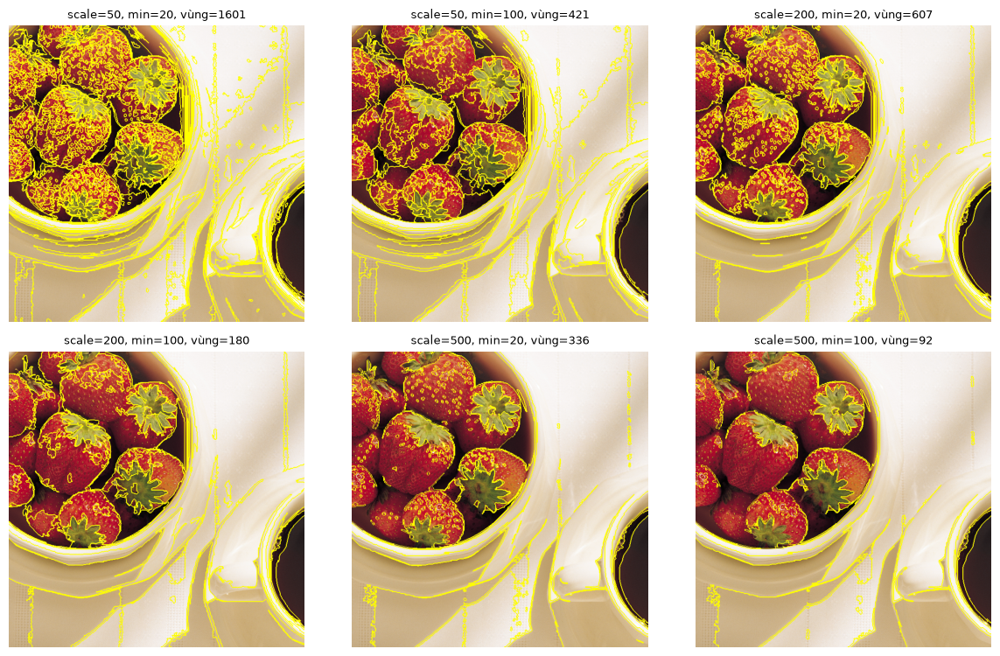

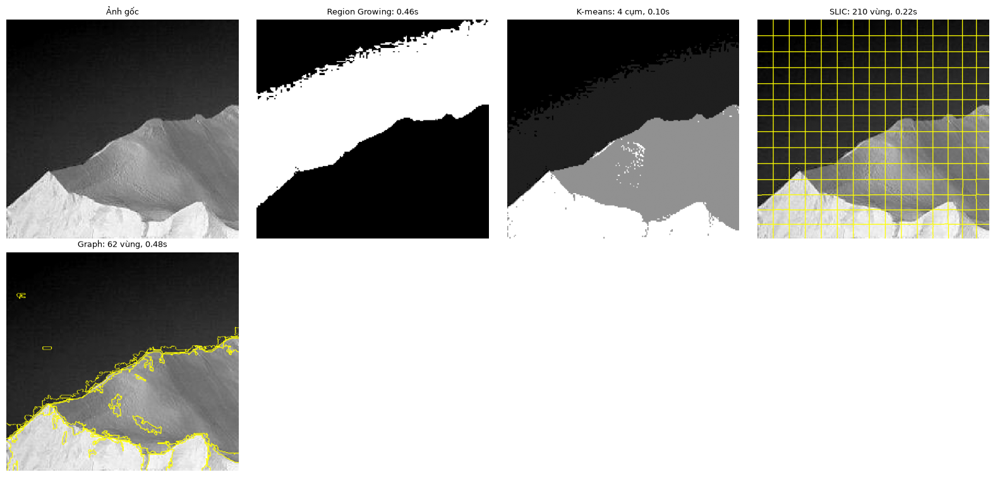

In [4]:
image=images["strawberries"]
panels=[]; titles=[]
for scale in (50,200,500):
    for minimum in (20,100):
        labels=felzenszwalb(image,scale=scale,sigma=.8,min_size=minimum,channel_axis=-1)
        panels.append(mark_boundaries(image,labels))
        titles.append(f"scale={scale}, min={minimum}, vùng={len(np.unique(labels))}")
figure("4.3_advanced_and_comparison","4.3_strawberries_input_vs_output_felzenszwalb_survey.png",panels,titles,3)
panels=[ice]; titles=["Ảnh gốc"]
start=time.perf_counter(); region=my_region_growing(ice,[ice_seed],30); elapsed=time.perf_counter()-start
panels.append(region); titles.append(f"Region Growing: {elapsed:.2f}s")
start=time.perf_counter(); km,lab=run_kmeans_segmentation(ice,4); elapsed=time.perf_counter()-start
panels.append(km); titles.append(f"K-means: 4 cụm, {elapsed:.2f}s")
start=time.perf_counter(); sl=run_slic_superpixels(ice,200,10); elapsed=time.perf_counter()-start
panels.append(mark_boundaries(np.repeat(ice[...,None],3,axis=2),sl)); titles.append(f"SLIC: {len(np.unique(sl))} vùng, {elapsed:.2f}s")
start=time.perf_counter(); graph=felzenszwalb(ice,scale=200,sigma=.8,min_size=100,channel_axis=None); elapsed=time.perf_counter()-start
panels.append(mark_boundaries(np.repeat(ice[...,None],3,axis=2),graph)); titles.append(f"Graph: {len(np.unique(graph))} vùng, {elapsed:.2f}s")
figure("4.3_advanced_and_comparison","4.3_methods_comparison_iceberg.png",panels,titles)


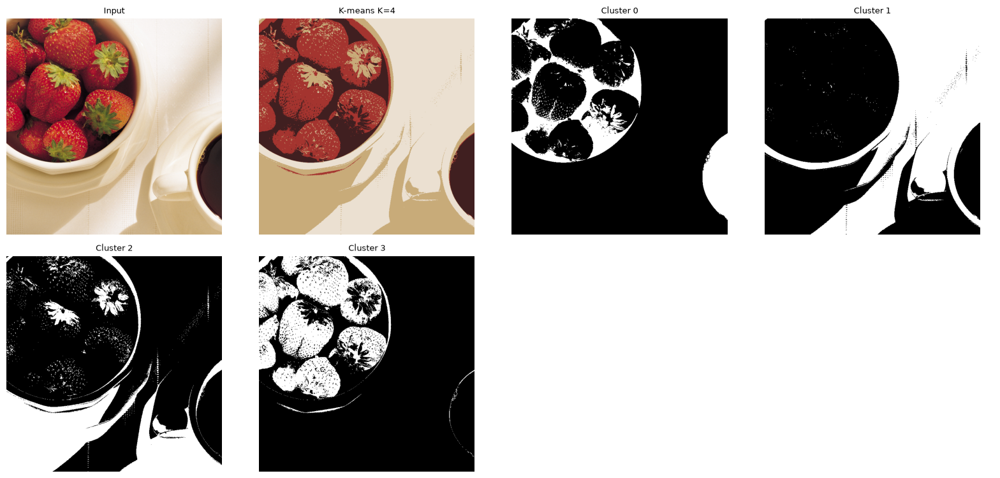

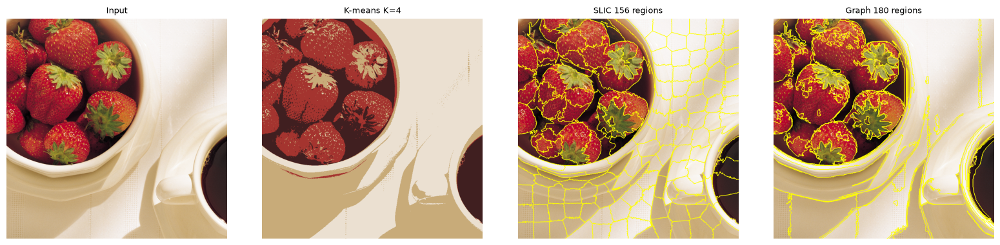

In [5]:
image=images["strawberries"]
reconstructed,clusters=run_kmeans_segmentation(image,4)
panels=[image,reconstructed]+[(clusters==k).astype(np.uint8)*255 for k in range(4)]
titles=["Input","K-means K=4"]+[f"Cluster {k}" for k in range(4)]
figure("4.2_kmeans_and_slic","4.2_strawberries_kmeans_masks.png",panels,titles)
slic_labels=run_slic_superpixels(image,200,10)
graph_labels=felzenszwalb(image,scale=200,sigma=.8,min_size=100,channel_axis=-1)
figure("4.3_advanced_and_comparison","4.3_methods_comparison_strawberries.png",
       [image,reconstructed,mark_boundaries(image,slic_labels),mark_boundaries(image,graph_labels)],
       ["Input","K-means K=4",f"SLIC {len(np.unique(slic_labels))} regions",f"Graph {len(np.unique(graph_labels))} regions"])


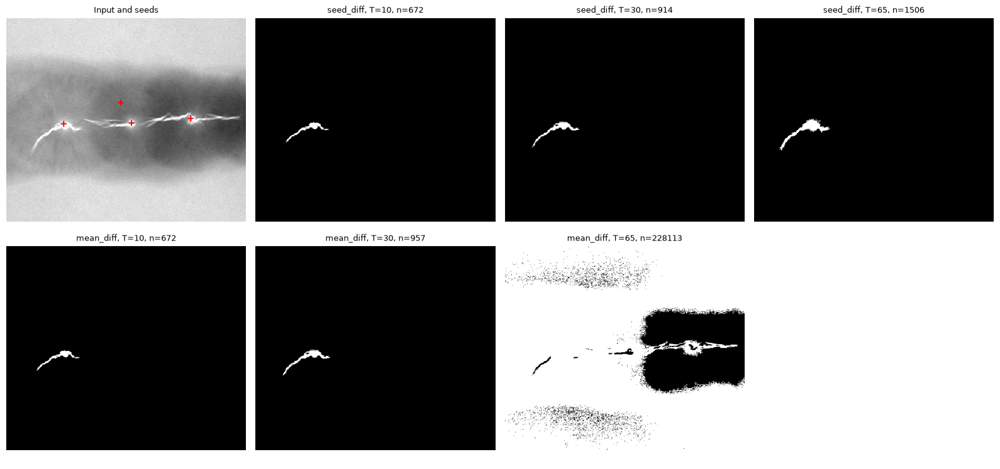

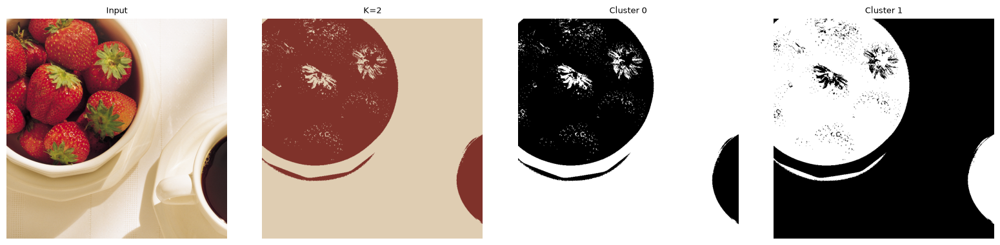

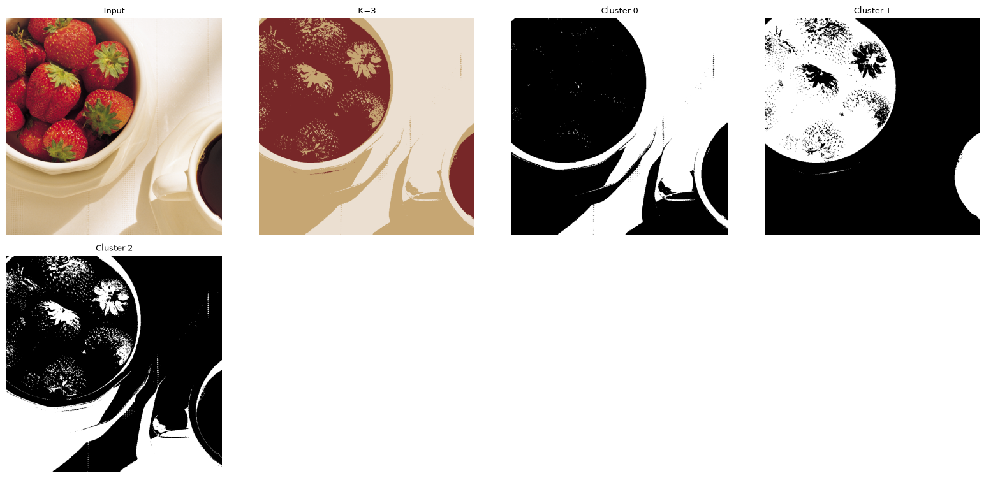

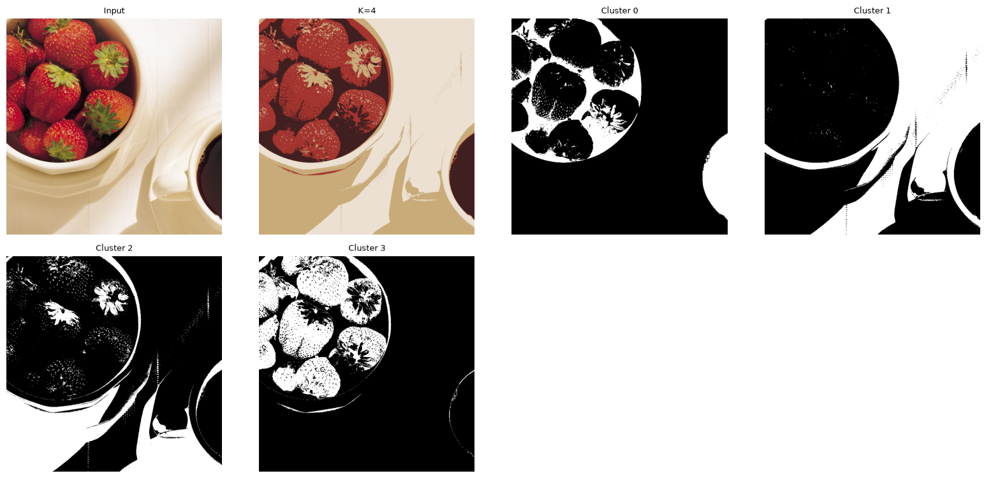

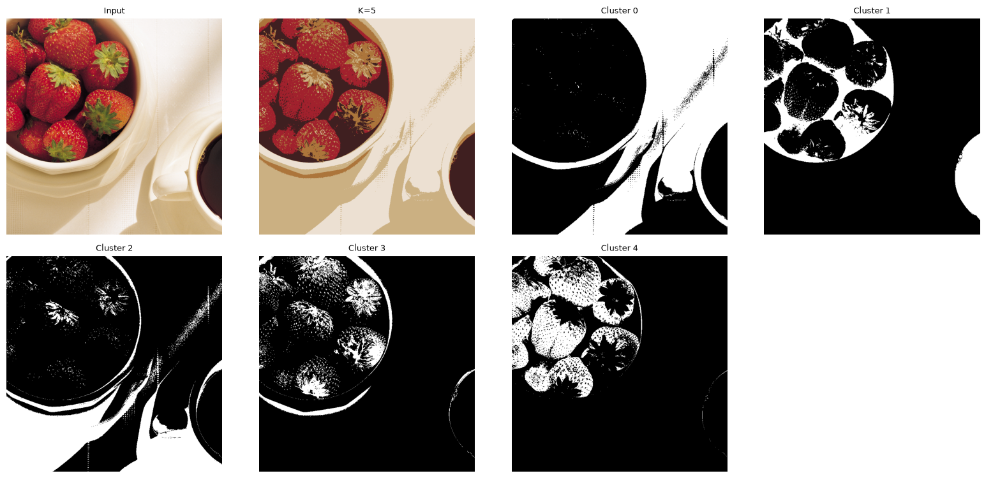

In [6]:
panels=[marked]; titles=["Input and seeds"]
for mode in ("seed_diff","mean_diff"):
    for t in (10,30,65):
        mask=my_region_growing(weld,[seeds[0]],t,mode=mode)
        panels.append(mask)
        titles.append(f"{mode}, T={t}, n={np.count_nonzero(mask)}")
figure("4.1_region_growing","4.1_weld_compare_seed_mean.png",panels,titles)
image=images["strawberries"]
for k in (2,3,4,5):
    reconstructed,labels=run_kmeans_segmentation(image,k)
    panels=[image,reconstructed]+[(labels==j).astype(np.uint8)*255 for j in range(k)]
    titles=["Input",f"K={k}"]+[f"Cluster {j}" for j in range(k)]
    figure("4.2_kmeans_and_slic",f"4.2_strawberries_kmeans_k{k}_masks.png",panels,titles)


Phân tích vùng bị bỏ sót hoặc lan sang nền trên hình; không kết luận độ chính xác giữa các phương pháp khi chưa có cùng mask tham chiếu. Bổ sung ảnh chụp màn hình cá nhân khi làm báo cáo.
